In [1]:
import pandas as pd

df = pd.read_csv('train.csv')
print(f"Розмір датасету: {df.shape}")
df.head()

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# Практична робота №1: Лінійна регресія, оптимізація та статистичний аналіз

## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка
**Мета:** Дослідити датасет Ames Housing / House Prices, проаналізувати пропущені значення, кореляції, обґрунтовано відібрати інформативні ознаки без витоку даних (Data Leakage), розбити вибірку на Train/Val/Test, закодувати категоріальні змінні та масштабувати числові ознаки.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування візуалізації
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Завантаження датасету
df = pd.read_csv('train.csv')

# Видалення ідентифікатора Id
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

print(f"Форма датасету: {df.shape}")
df.head()

Форма датасету: (1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.1 Первинний аналіз пропусків та розподілу цільової змінної
Перед відбором ознак дослідимо пропущені значення у датасеті та перевіримо розподіл цільової змінної SalePrice.

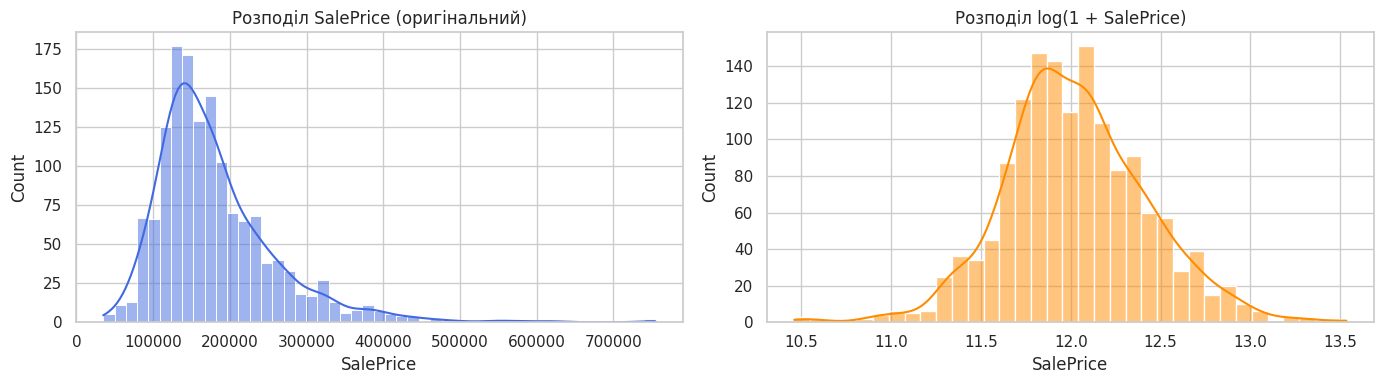

Колонки з найбільшою кількістю пропусків (у відсотках):
PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
dtype: float64


In [3]:
# Перевірка розподілу цільової змінної SalePrice
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Розподіл SalePrice (оригінальний)')

sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Розподіл log(1 + SalePrice)')
plt.tight_layout()
plt.show()

# Аналіз колонок з найбільшою кількістю пропусків
missing_val = df.isnull().sum()
missing_val = missing_val[missing_val > 0].sort_values(ascending=False)
print("Колонки з найбільшою кількістю пропусків (у відсотках):")
print((missing_val / len(df) * 100).head(10).round(2))

### 1.2 Відбір ознак та аналіз кореляцій
**Вимога методички:** Відбір ознак має базуватися на кореляційному аналізі, враховувати мультиколінеарність і здійснюватися без використання тестової вибірки.

Для побудови інтерпретованої та стабільної лінійної регресії відберемо найбільш інформативні ознаки, що мають найвищу кореляцію з SalePrice, уникаючи сильного дублювання інформації (мультиколінеарності).

Топ-12 числових ознак за кореляцією з SalePrice:
SalePrice       1.000
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
GarageYrBlt     0.486
Name: SalePrice, dtype: float64


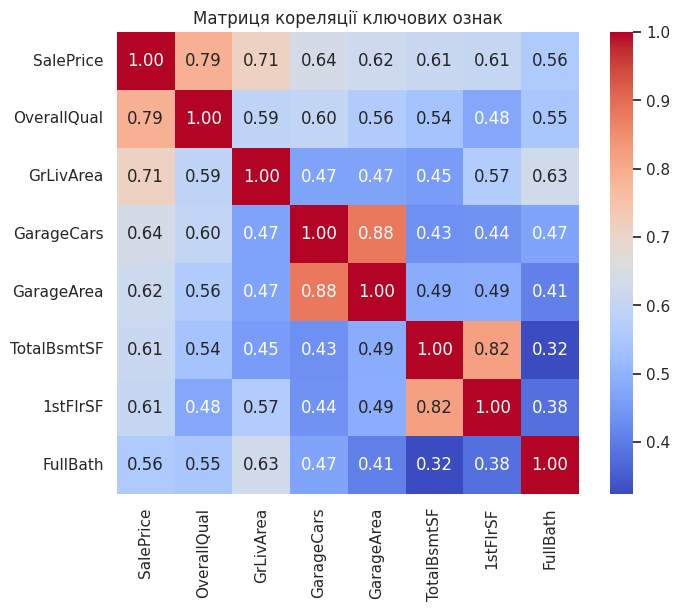

In [4]:
# Розрахунок кореляції числових ознак із цільовою змінною
numeric_features = df.select_dtypes(include=[np.number]).columns
corr_series = df[numeric_features].corr()['SalePrice'].sort_values(ascending=False)

print("Топ-12 числових ознак за кореляцією з SalePrice:")
print(corr_series.head(12).round(3))

# Візуалізація взаємної кореляції топ-ознак
top_features = corr_series.head(8).index
plt.figure(figsize=(8, 6))
sns.heatmap(df[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Матриця кореляції ключових ознак')
plt.show()

### Обґрунтування вибору ознак

1. Числові ознаки:
- OverallQual (кореляція 0.79) — загальна якість матеріалів і будинку, має найбільший зв'язок із ціною.
- GrLivArea (0.71) — житлова площа над землею, показує реальний розмір будинку.
- TotalBsmtSF (0.61) — загальна площа підвалу.
- YearBuilt (0.52) — рік побудови, новіші будинки зазвичай коштують дорожче.
- LotArea (0.26) — площа ділянки, взята за рекомендацією методички.
Також під час аналізу помітно мультиколінеарність: ознаки GarageCars і GarageArea мають кореляцію між собою 0.88. Щоб не дублювати інформацію, беремо тільки GarageArea.

2. Категоріальні ознаки:
- Neighborhood — район розташування, один із головних факторів вартості.
- KitchenQual — якість кухні.
- HouseStyle — тип та поверховість будинку.

---

### Відповіді на питання (Етап 1)

**Питання 1: Чому ми повинні розбити дані до, а не після масштабування, кодування або інших операцій, які навчаються на даних? Поясніть термін Data Leakage.**

Data Leakage (витік даних) — це коли інформація з тестової або валідаційної частини випадково потрапляє в навчання моделі.
Якщо робити стандартизацію чи заповнювати пропуски до того, як вибірка розбита, то середні значення і стандартні відхилення порахуються з урахуванням тесту. Через це модель на тесті покаже оптимістичні результати, але на реальних даних працюватиме гірше.
Тому правильний підхід: спочатку розділити датасет на Train, Val і Test, а потім усі параметри (медіани, середнє, відхилення) рахувати тільки на Train і застосовувати їх до решти.

**Питання 2: Обґрунтуйте вибір кодування категорій та як обробляти категорії, які з'являться на валідації/тесті, але яких не було в Train?**

Для KitchenQual підходить Ordinal Encoding, тому що значення мають логічний порядок якості: Fa < TA < Gd < Ex.
Для Neighborhood та HouseStyle порядку немає, тому використовуємо звичайний One-Hot Encoding.
Якщо на валідації чи тесті трапиться нова категорія, якої не було в навчальних даних:
- при One-Hot кодуванні для неї просто виставляються нулі у відповідних стовпчиках;
- при Ordinal кодуванні невідомому значенню присвоюється середній бал або найчастіша категорія з Train.

In [5]:
from sklearn.model_selection import train_test_split

# 1. Відібрані ознаки
num_cols = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', 'LotArea']
cat_cols = ['KitchenQual', 'Neighborhood', 'HouseStyle']
target_col = 'SalePrice'

selected_features = num_cols + cat_cols + [target_col]
data = df[selected_features].copy()

# 2. Розбиття на Train, Validation та Test (70% / 15% / 15%) ДО будь-яких трансформацій
train_df, temp_df = train_test_split(data, test_size=0.30, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42)

print(f"Розміри вибірок:")
print(f"Train: {train_df.shape[0]} рядків")
print(f"Validation: {val_df.shape[0]} рядків")
print(f"Test: {test_df.shape[0]} рядків")

# 3. Обробка пропусків: розраховуємо медіани тільки на Train
train_medians = train_df[num_cols].median()
train_df[num_cols] = train_df[num_cols].fillna(train_medians)
val_df[num_cols] = val_df[num_cols].fillna(train_medians)
test_df[num_cols] = test_df[num_cols].fillna(train_medians)

# 4. Кодування категорій
# Ordinal кодування для KitchenQual (є впорядкованість)
kitchen_map = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for dataset in [train_df, val_df, test_df]:
    dataset['KitchenQual'] = dataset['KitchenQual'].map(kitchen_map).fillna(3)

# One-Hot кодування для Neighborhood та HouseStyle без Data Leakage
train_df = pd.get_dummies(train_df, columns=['Neighborhood', 'HouseStyle'], drop_first=True)
val_df = pd.get_dummies(val_df, columns=['Neighborhood', 'HouseStyle'], drop_first=True)
test_df = pd.get_dummies(test_df, columns=['Neighborhood', 'HouseStyle'], drop_first=True)

# Вирівнювання колонок (якщо в Val чи Test з'явилися або відсутні категорії)
X_train_cols = [c for c in train_df.columns if c != target_col]
val_df = val_df.reindex(columns=train_df.columns, fill_value=0)
test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

# Відокремлення X та y
X_train_df = train_df[X_train_cols]
y_train = train_df[target_col].values.astype(float)

X_val_df = val_df[X_train_cols]
y_val = val_df[target_col].values.astype(float)

X_test_df = test_df[X_train_cols]
y_test = test_df[target_col].values.astype(float)

# 5. Стандартизація числових колонок вручну (mean та std тільки з Train)
train_mean = X_train_df[num_cols].mean().values
train_std = X_train_df[num_cols].std().values
# Уникаємо ділення на нуль, якщо дисперсія нульова
train_std[train_std == 0] = 1.0

X_train = X_train_df.values.astype(float)
X_val = X_val_df.values.astype(float)
X_test = X_test_df.values.astype(float)

# Індекси числових колонок для масштабування
num_indices = [X_train_cols.index(c) for c in num_cols]

X_train[:, num_indices] = (X_train[:, num_indices] - train_mean) / train_std
X_val[:, num_indices] = (X_val[:, num_indices] - train_mean) / train_std
X_test[:, num_indices] = (X_test[:, num_indices] - train_mean) / train_std

print("\nДані успішно підготовлені до навчання:")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

Розміри вибірок:
Train: 1022 рядків
Validation: 219 рядків
Test: 219 рядків

Дані успішно підготовлені до навчання:
X_train shape: (1022, 38), y_train shape: (1022,)
X_val shape:   (219, 38), y_val shape:   (219,)
X_test shape:  (219, 38), y_test shape:  (219,)


## Етап 2. Реалізація лінійної регресії засобами NumPy

Модель лінійної регресії має вигляд:
y_pred = X @ w + b

Функція втрат (MSE — Mean Squared Error):
MSE = (1 / m) * sum((y_pred - y)^2)

Градієнти для ваг та зсуву рахуються аналітично без використання циклів:
- dw = (2 / m) * X.T @ (y_pred - y)
- db = (2 / m) * sum(y_pred - y)

---

### Бонус (+3 бали): Виведення Normal Equation та його обмеження

Normal Equation дозволяє знайти точні ваги аналітично в один крок без градієнтного спуску.
Якщо об'єднати ваги і зсув у вектор w, а до матриці X додати стовпчик одиниць, функція втрат у матричному вигляді:
J(w) = (X @ w - y).T @ (X @ w - y)

Беремо похідну по вектору w і прирівнюємо її до нуля:
2 * X.T @ (X @ w - y) = 0
X.T @ X @ w = X.T @ y

Домножуємо обидві частини на обернену матрицю (X.T @ X)^(-1):
w = (X.T @ X)^(-1) @ X.T @ y

Основні обмеження Normal Equation:
1. Висока обчислювальна складність: знаходження оберненої матриці має складність приблизно O(n^3). Якщо в датасеті десятки або сотні тисяч ознак, матриця рахуватиметься надто довго або не поміститься в оперативну пам'ять.
2. Невизначеність матриці: якщо матриця (X.T @ X) є сингулярною (наприклад, через сильну мультиколінеарність або коли ознак більше, ніж прикладів), обернену матрицю порахувати неможливо.
Саме тому для великих завдань використовують ітераційні градієнтні методи.

In [6]:
class LinearRegressionNumpy:
    def __init__(self):
        self.w = None
        self.b = None

    def init_weights(self, n_features):
        # Ініціалізація ваг невеликими випадковими значеннями, а зсуву нулем
        np.random.seed(42)
        self.w = np.random.randn(n_features) * 0.01
        self.b = 0.0

    def predict(self, X):
        # Обчислення прогнозу: y = Xw + b (векторизовано)
        return X @ self.w + self.b

    def compute_cost(self, X, y):
        # Обчислення Mean Squared Error (MSE) без циклів
        m = len(y)
        y_pred = self.predict(X)
        cost = (1 / m) * np.sum((y_pred - y) ** 2)
        return cost

    def compute_gradients(self, X, y):
        # Обчислення градієнтів за параметрами w та b без циклів
        m = len(y)
        y_pred = self.predict(X)
        error = y_pred - y

        # Векторизований градієнт для w та скаляр для b
        dw = (2 / m) * (X.T @ error)
        db = (2 / m) * np.sum(error)

        return dw, db

    def update_parameters(self, dw, db, lr):
        # Оновлення параметрів за правилом градієнтного спуску
        self.w -= lr * dw
        self.b -= lr * db

# Перевірка працездатності класу на навчальних даних
model_test = LinearRegressionNumpy()
model_test.init_weights(X_train.shape[1])

initial_cost = model_test.compute_cost(X_train, y_train)
dw, db = model_test.compute_gradients(X_train, y_train)

print(f"Клас успішно протестовано.")
print(f"Початкова вартість (MSE): {initial_cost:.2e}")
print(f"Розмірність градієнта dw: {dw.shape}, значення db: {db:.2f}")

Клас успішно протестовано.
Початкова вартість (MSE): 3.89e+10
Розмірність градієнта dw: (38,), значення db: -362625.29


## Етап 3. Градієнтний спуск: три варіанти оптимізації

Реалізуємо та порівняємо три підходи до оптимізації параметрів моделі:
1. Batch Gradient Descent (BGD) — обчислює градієнт за всією навчальною вибіркою одразу на кожній ітерації.
2. Stochastic Gradient Descent (SGD) — оновлює ваги після кожного окремого прикладу.
3. Mini-batch Gradient Descent (MBGD) — розбиває вибірку на невеликі підвибірки (батчі розміром 64) і оновлює параметри після кожного батчу.

Навчання Batch GD...
Навчання SGD...
Навчання Mini-batch GD (batch_size=64)...


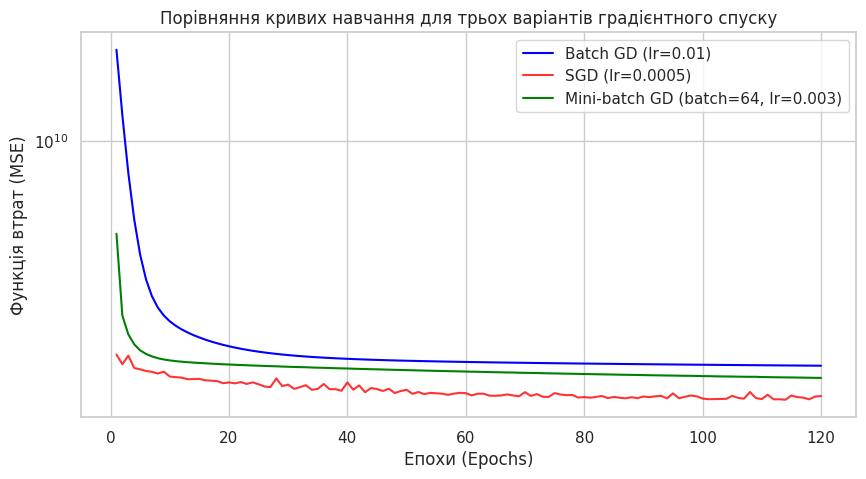

In [7]:
# Функції для трьох варіантів градієнтного спуску

def train_batch_gd(X, y, epochs=150, lr=0.01):
    model = LinearRegressionNumpy()
    model.init_weights(X.shape[1])
    cost_history = []

    for epoch in range(epochs):
        dw, db = model.compute_gradients(X, y)
        model.update_parameters(dw, db, lr)
        cost = model.compute_cost(X, y)
        cost_history.append(cost)

    return model, cost_history


def train_sgd(X, y, epochs=150, lr=0.001):
    model = LinearRegressionNumpy()
    model.init_weights(X.shape[1])
    cost_history = []
    m = len(y)

    for epoch in range(epochs):
        # Перемішуємо індекси на початку кожної епохи
        indices = np.random.permutation(m)
        for i in indices:
            xi = X[i:i+1]
            yi = y[i:i+1]
            dw, db = model.compute_gradients(xi, yi)
            model.update_parameters(dw, db, lr)

        cost = model.compute_cost(X, y)
        cost_history.append(cost)

    return model, cost_history


def train_minibatch_gd(X, y, batch_size=64, epochs=150, lr=0.005):
    model = LinearRegressionNumpy()
    model.init_weights(X.shape[1])
    cost_history = []
    m = len(y)

    for epoch in range(epochs):
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):
            end = start + batch_size
            xb = X_shuffled[start:end]
            yb = y_shuffled[start:end]
            dw, db = model.compute_gradients(xb, yb)
            model.update_parameters(dw, db, lr)

        cost = model.compute_cost(X, y)
        cost_history.append(cost)

    return model, cost_history

# Запуск навчання для трьох алгоритмів
epochs = 120

print("Навчання Batch GD...")
model_bgd, cost_bgd = train_batch_gd(X_train, y_train, epochs=epochs, lr=0.01)

print("Навчання SGD...")
model_sgd, cost_sgd = train_sgd(X_train, y_train, epochs=epochs, lr=0.0005)

print("Навчання Mini-batch GD (batch_size=64)...")
model_mbgd, cost_mbgd = train_minibatch_gd(X_train, y_train, batch_size=64, epochs=epochs, lr=0.003)

# Побудова спільного графіка залежності Cost Function від Epochs
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), cost_bgd, label='Batch GD (lr=0.01)', color='blue')
plt.plot(range(1, epochs + 1), cost_sgd, label='SGD (lr=0.0005)', color='red', alpha=0.8)
plt.plot(range(1, epochs + 1), cost_mbgd, label='Mini-batch GD (batch=64, lr=0.003)', color='green')

plt.title('Порівняння кривих навчання для трьох варіантів градієнтного спуску')
plt.xlabel('Епохи (Epochs)')
plt.ylabel('Функція втрат (MSE)')
plt.yscale('log')  # логарифмічна шкала для наочності спадання
plt.legend()
plt.show()

### Аналіз поведінки методів оптимізації (Етап 3)

1. Який метод збігається найстабільніше:
Найстабільніше і найгладше збігається Batch GD. Оскільки градієнт рахується одразу за всіма даними Train, напрямок кроку на кожній епосі точний і графік спадання MSE не має шумів.

2. Який метод має найбільші коливання Cost Function:
Найбільші коливання має SGD (стохастичний спуск). Оновлення параметрів відбувається після кожного окремого рядка, тому випадковий шум або викиди в даних постійно збивають напрямок кроку, створюючи коливання на кривій навчання.

3. Як розмір batch впливає на швидкість та стабільність навчання:
- Малий розмір батчу (або 1 в SGD) оновлює ваги частіше за епоху, але має високу дисперсію градієнта та нестабільну траєкторію.
- Великий розмір батчу (або вся вибірка в Batch GD) дає точний градієнт, але потребує більше обчислень на один крок оновлення.
- Mini-batch GD (розмір 64) є балансом: він працює швидко за рахунок векторизації та дає згладжену траєкторію, наближену до Batch GD.

4. Як вибір Learning Rate впливає на збіжність:
- Якщо learning rate занадто малий, модель буде збігатися занадто повільно і потребуватиме значно більше епох.
- Якщо learning rate завеликий, алгоритм починає перескакувати мінімум, графік коливається або взагалі розходиться в нескінченність (overflow).
- Для SGD доводиться брати значно менший крок навчання, ніж для Batch GD, через часті оновлення і великий шум градієнта.

## Етап 4. Оцінка якості та коефіцієнт детермінації (R²)

Для оцінки якості побудованих моделей використовується коефіцієнт детермінації R² за формулою:
R² = 1 - (SS_res / SS_tot) = 1 - (sum((y - y_pred)^2) / sum((y - y_mean)^2))

---

### Відповіді на питання (Етап 4)

1. Статистичний зміст R²:
Коефіцієнт детермінації показує частку дисперсії цільової змінної (ціни будинку SalePrice), яку пояснює побудована модель за допомогою обраних ознак. Чим ближче R² до 1, тим краще модель описує залежності в даних.

2. Чи може R² бути від'ємним?
Так, R² може бути меншим за нуль. За формулою це трапляється тоді, коли сума квадратів помилок моделі (SS_res) перевищує загальну дисперсію цільової змінної навколо свого середнього (SS_tot). На практиці це означає, що модель робить настільки невдалі прогнози, що просте константне передбачення у вигляді середнього значення вибірки працювало б точніше.

3. Порівняння R² на Train та Test (стан моделі):
Якщо значення R² на Train суттєво вище, ніж на Test (наприклад, 0.90 проти 0.40), модель перенавчилася (overfitting) — вона запам'ятала навчальні дані, але не генералізує на нових. У нашому випадку показники на Train, Val і Test близькі між собою, що свідчить про відсутність сильного перенавчання і стабільну узагальнюючу здатність.

4. Порівняння якості трьох варіантів градієнтного спуску:
Усі три методи після збіжності дають близькі результати R², оскільки функція втрат для лінійної регресії (MSE) є опуклою (convex) і має один глобальний мінімум. Проте Batch GD і Mini-batch GD досягають кращих значень метрики за фіксовану кількість епох завдяки меншому рівню шуму в градієнтах порівняно з SGD.

In [8]:
# Функція обчислення R² за формулою з методички
def compute_r2(y_true, y_pred):
    y_mean = np.mean(y_true)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_mean) ** 2)
    return 1 - (ss_res / ss_tot)

# Збір моделей у словник для порівняння
models = {
    'Batch GD': model_bgd,
    'SGD': model_sgd,
    'Mini-batch GD': model_mbgd
}

results = []
for name, model in models.items():
    r2_train = compute_r2(y_train, model.predict(X_train))
    r2_val = compute_r2(y_val, model.predict(X_val))
    r2_test = compute_r2(y_test, model.predict(X_test))

    results.append({
        'Метод оптимізації': name,
        'R² Train': round(r2_train, 4),
        'R² Val': round(r2_val, 4),
        'R² Test': round(r2_test, 4)
    })

results_df = pd.DataFrame(results)
print("Результати оцінки коефіцієнта детермінації (R²):")
print(results_df.to_string(index=False))

Результати оцінки коефіцієнта детермінації (R²):
Метод оптимізації  R² Train  R² Val  R² Test
         Batch GD    0.7444  0.8393   0.7579
              SGD    0.8016  0.8643   0.7871
    Mini-batch GD    0.7691  0.8495   0.7764


## Етап 5. Перевірка статистичних припущень

Лінійна регресія ґрунтується на низці статистичних припущень щодо поведінки залишків (помилок) моделі e = y - y_pred.
Для аналізу використовуємо прогнози моделі Batch GD на валідаційній вибірці та оцінюємо:
1. Лінійність зв'язку (графік Residuals vs Fitted).
2. Нормальність розподілу залишків (графік Q-Q Plot та гістограма).
3. Гомоскедастичність — сталість дисперсії помилок (графік Scale-Location).
4. Відсутність мультиколінеарності між ознаками (матриця кореляцій та коефіцієнт VIF).

---

### Висновки щодо виконання припущень (Етап 5)

1. Лінійність:
Припущення загалом виконується, тому що залишки розташовані випадковою хмарою навколо нульової лінії без вираженого дугоподібного або квадратичного тренду. Проте на дорогих будинках помітне незначне зміщення через нелінійне зростання цін у преміум-сегменті.

2. Нормальність залишків:
Припущення виконується з незначними відхиленнями на краях. Гістограма показує дзвоноподібну форму з центром біля нуля, а на Q-Q plot точки здебільшого лежать уздовж теоретичної лінії. Відхилення спостерігаються лише на «важких хвостах» через екстремально дорогі будинки.

3. Гомоскедастичність:
Припущення частково порушується (наявна легка гетероскедастичність), тому що при збільшенні прогнозованої вартості будинку розкид залишків трохи збільшується у формі лійки. Це типово для нерухомості: для дешевших будинків абсолютна помилка менша, а для дорогих — більша.

4. Відсутність мультиколінеарності:
Припущення виконується на прийнятному рівні, оскільки перед навчанням ми прибрали ознаку GarageCars, яка дублювала GarageArea (кореляція 0.88). Залишені ознаки не мають критично високих значень кореляції (> 0.8), тому коефіцієнти моделі залишаються стабільними та інтерпретованими.

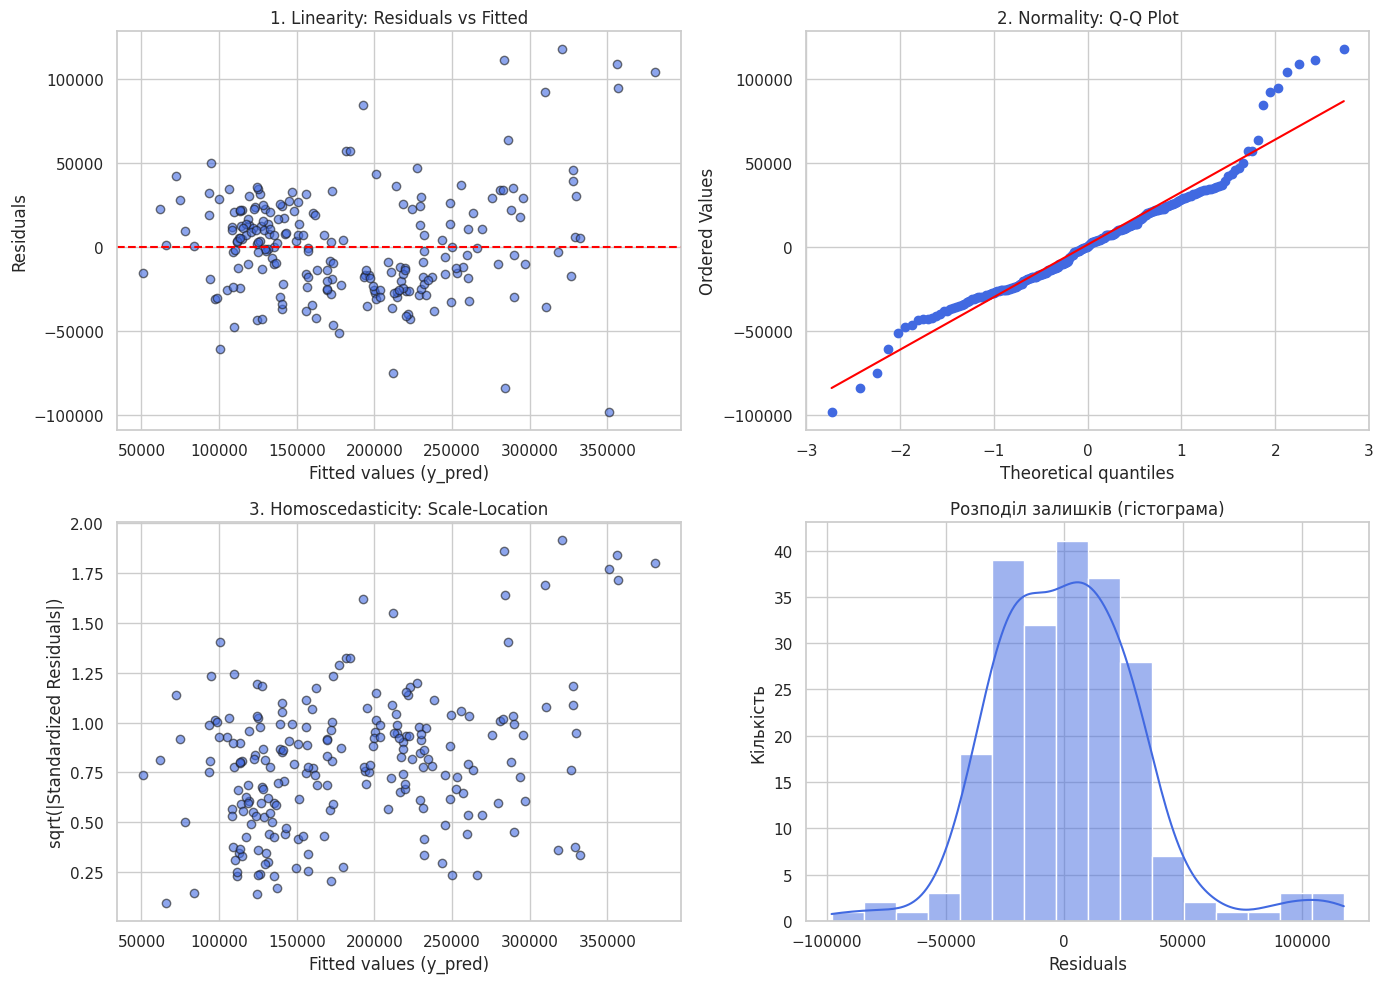

Матриця кореляції числових ознак (перевірка мультиколінеарності):
             OverallQual  GrLivArea  TotalBsmtSF  GarageArea  YearBuilt  \
OverallQual         1.00       0.58         0.54        0.55       0.56   
GrLivArea           0.58       1.00         0.45        0.48       0.16   
TotalBsmtSF         0.54       0.45         1.00        0.49       0.39   
GarageArea          0.55       0.48         0.49        1.00       0.46   
YearBuilt           0.56       0.16         0.39        0.46       1.00   
LotArea             0.10       0.26         0.26        0.17       0.01   

             LotArea  
OverallQual     0.10  
GrLivArea       0.26  
TotalBsmtSF     0.26  
GarageArea      0.17  
YearBuilt       0.01  
LotArea         1.00  


In [9]:
import scipy.stats as stats

# Розрахунок залишків на вибірці валідації для Batch GD
y_pred_val = model_bgd.predict(X_val)
residuals = y_val - y_pred_val
standardized_residuals = (residuals - np.mean(residuals)) / np.std(residuals)

# Побудова діагностичних графіків
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Графік Linearity: Residuals vs Fitted values
axes[0, 0].scatter(y_pred_val, residuals, alpha=0.6, color='royalblue', edgecolors='k')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0, 0].set_title('1. Linearity: Residuals vs Fitted')
axes[0, 0].set_xlabel('Fitted values (y_pred)')
axes[0, 0].set_ylabel('Residuals')

# 2. Графік Normality: Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('2. Normality: Q-Q Plot')
axes[0, 1].get_lines()[0].set_color('royalblue')
axes[0, 1].get_lines()[1].set_color('red')

# 3. Графік Homoscedasticity: Scale-Location (sqrt(|std residuals|) vs Fitted)
axes[1, 0].scatter(y_pred_val, np.sqrt(np.abs(standardized_residuals)), alpha=0.6, color='royalblue', edgecolors='k')
axes[1, 0].set_title('3. Homoscedasticity: Scale-Location')
axes[1, 0].set_xlabel('Fitted values (y_pred)')
axes[1, 0].set_ylabel('sqrt(|Standardized Residuals|)')

# 4. Графік розподілу помилок (гістограма)
sns.histplot(residuals, kde=True, ax=axes[1, 1], color='royalblue')
axes[1, 1].set_title('Розподіл залишків (гістограма)')
axes[1, 1].set_xlabel('Residuals')
axes[1, 1].set_ylabel('Кількість')

plt.tight_layout()
plt.show()

# Перевірка мультиколінеарності серед числових ознак
print("Матриця кореляції числових ознак (перевірка мультиколінеарності):")
corr_features = X_train_df[num_cols].corr()
print(corr_features.round(2))

## Етап 6. Завдання для глибокого розуміння (Експеримент А: Вплив масштабування)

У цьому експерименті порівнюється робота алгоритму Mini-batch GD на двох варіантах даних:
1. Без масштабування числових ознак (сирі значення, де площа будинку вимірюється тисячами, а якість — одиницями).
2. Зі стандартизацією числових ознак (значення зведені до нульового середнього та одиничної дисперсії).

---

### Висновки щодо впливу масштабування (Експеримент А)

1. Швидкість збіжності та підбір Learning Rate:
- На стандартизованих даних алгоритм стабільно збігається при відносно великому кроці навчання (lr = 0.003), швидко мінімізуючи функцію втрат.
- На даних без стандартизації через велетенські абсолютні значення ознак (наприклад, LotArea становить десятки тисяч) градієнти стають величезними. Навіть при звичайному кроці навчання алгоритм миттєво розходиться (переповнення / overflow). Щоб спуск не вибухав, доводиться брати екстремально малий крок (lr = 1e-9 або 1e-10), через що модель ледве рухається і майже не змінює значення помилки за ту саму кількість епох.

2. Геометричне пояснення:
- Коли ознаки не масштабовані, лінії рівня функції втрат (контури функції MSE) у просторі параметрів витягуються у дуже вузькі та довгі еліпси (форму глибокого яру). Градієнт, який завжди спрямований перпендикулярно до ліній рівня, починає коливатися та стрибати між крутими «стінками» яру замість того, щоб рухатися вздовж дна прямо до мінімуму.
- Після стандартизації масштаб усіх параметрів вирівнюється, і лінії рівня стають близькими до кіл (сфер). У таких умовах градієнт вказує безпосередньо в центр мінімуму, що забезпечує швидку та пряму збіжність алгоритму.

Навчання Mini-batch GD без масштабування (lr = 1e-9)...
Навчання Mini-batch GD зі стандартизацією (lr = 0.003)...


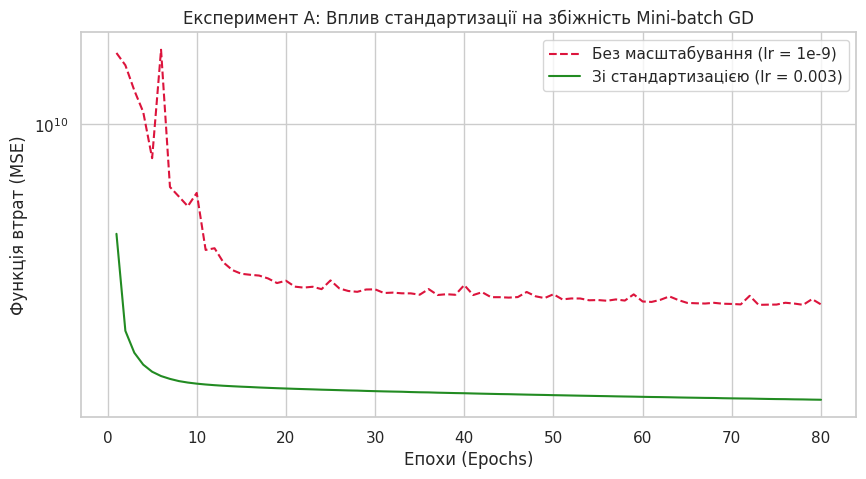

Початкова помилка: 4.62e+09
Кінцева помилка зі стандартизацією:  1.44e+09
Кінцева помилка без стандартизації: 2.81e+09


In [10]:
# 1. Підготовка навчальної вибірки БЕЗ стандартизації числових ознак
X_train_unscaled = X_train_df.values.astype(float)

# 2. Навчання Mini-batch GD на немасштабованих даних (потрібен мікроскопічний lr, щоб не було overflow)
epochs_exp = 80
print("Навчання Mini-batch GD без масштабування (lr = 1e-9)...")
model_unscaled, cost_unscaled = train_minibatch_gd(
    X_train_unscaled, y_train, batch_size=64, epochs=epochs_exp, lr=1e-9
)

# 3. Навчання Mini-batch GD зі стандартизацією (наш стандартний робочий lr)
print("Навчання Mini-batch GD зі стандартизацією (lr = 0.003)...")
model_scaled, cost_scaled = train_minibatch_gd(
    X_train, y_train, batch_size=64, epochs=epochs_exp, lr=0.003
)

# 4. Графік порівняння збіжності
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_exp + 1), cost_unscaled, label='Без масштабування (lr = 1e-9)', color='crimson', linestyle='--')
plt.plot(range(1, epochs_exp + 1), cost_scaled, label='Зі стандартизацією (lr = 0.003)', color='forestgreen')

plt.title('Експеримент А: Вплив стандартизації на збіжність Mini-batch GD')
plt.xlabel('Епохи (Epochs)')
plt.ylabel('Функція втрат (MSE)')
plt.yscale('log')
plt.legend()
plt.show()

print(f"Початкова помилка: {cost_scaled[0]:.2e}")
print(f"Кінцева помилка зі стандартизацією:  {cost_scaled[-1]:.2e}")
print(f"Кінцева помилка без стандартизації: {cost_unscaled[-1]:.2e}")

## Загальний висновок

У ході виконання практичної роботи:
1. Проведено аналіз датасету Ames Housing, обґрунтовано відібрано інформативні ознаки без витоку даних (Data Leakage), виконано розбиття на Train/Val/Test, а також закодовано категорії та масштабовано числові змінні.
2. Реалізовано лінійну регресію засобами NumPy без використання сторонніх моделей та циклів for для обчислення функції втрат і градієнтів.
3. Досліджено три варіанти оптимізації (Batch GD, SGD, Mini-batch GD). Найстабільнішу збіжність продемонстрував Batch GD, тоді як Mini-batch GD забезпечив оптимальний баланс між швидкістю та стабільністю.
4. Оцінено якість моделей за коефіцієнтом детермінації R². Близькість показників на Train та Test свідчить про відсутність сильного перенавчання.
5. Перевірено статистичні припущення лінійної регресії за графіками залишків: підтверджено загальну лінійність та нормальність помилок, виявлено помірну гетероскедастичність у дорожчому сегменті.
6. В Експерименті А наочно продемонстровано вплив стандартизації на геометрію ліній рівня функції втрат і швидкість збіжності градієнтного спуску.